In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df_employee = pd.read_csv("Employee.csv")
df_performance = pd.read_csv('Performance Rating.csv')
df_education = pd.read_csv('Education.csv')
df_satisfaction = pd.read_csv('Satisfaction.csv')
df_rating = pd.read_csv('Rating.csv')
df= df_employee.merge(df_education,left_on="Education",right_on="EducationLevelID",how="left")
df.drop(columns="Education")
df = df.merge(df_performance,on="EmployeeID",how="left")
df = df.merge(df_satisfaction,left_on="RelationshipSatisfaction",right_on="SatisfactionID",how="left")
df.drop(columns="RelationshipSatisfaction",inplace=True)
self_rating = df_rating.rename(columns={
    "RatingID": "SelfRating",
    "RatingLevel": "SelfRatingLevel"
})

df = df.merge(
    self_rating,
    on="SelfRating",
    how="left"
)
manager_rating = df_rating.rename(columns={
    "RatingID": "ManagerRating",
    "RatingLevel": "ManagerRatingLevel"
})

df = df.merge(
    manager_rating,
    on="ManagerRating",
    how="left"
)
df.columns

Index(['EmployeeID', 'FirstName', 'LastName', 'Gender', 'Age',
       'BusinessTravel', 'Department', 'DistanceFromHome (KM)', 'State',
       'Ethnicity', 'Education', 'EducationField', 'JobRole', 'MaritalStatus',
       'Salary', 'StockOptionLevel', 'OverTime', 'HireDate', 'Attrition',
       'YearsAtCompany', 'YearsInMostRecentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager', 'EducationLevelID', 'EducationLevel',
       'PerformanceID', 'ReviewDate', 'EnvironmentSatisfaction',
       'JobSatisfaction', 'TrainingOpportunitiesWithinYear',
       'TrainingOpportunitiesTaken', 'WorkLifeBalance', 'SelfRating',
       'ManagerRating', 'SatisfactionID', 'SatisfactionLevel',
       'SelfRatingLevel', 'ManagerRatingLevel'],
      dtype='str')

1. Gender, MaritalStatus, Departament və BusinessTravel kimi kateqoriyalı dəyişənlərin paylanmasını hesablayın.


In [3]:
df.groupby("Gender").size()
gender = df.groupby("Gender").size()

gender_percent = (gender / gender.sum()) * 100

print(gender_percent)

Gender
Female               45.963183
Male                 44.325265
Non-Binary            8.754892
Prefer Not To Say     0.956660
dtype: float64




Gender
Female               45.96
Male                 44.33
Non-Binary            8.75
Prefer Not To Say     0.96
Name: proportion, dtype: float64


MaritalStatus
Married     42.35
Single      38.37
Divorced    19.28
Name: proportion, dtype: float64


Department
Technology         63.41
Sales              32.05
Human Resources     4.54
Name: proportion, dtype: float64


BusinessTravel
Some Travel           70.60
Frequent Traveller    20.21
No Travel              9.19
Name: proportion, dtype: float64


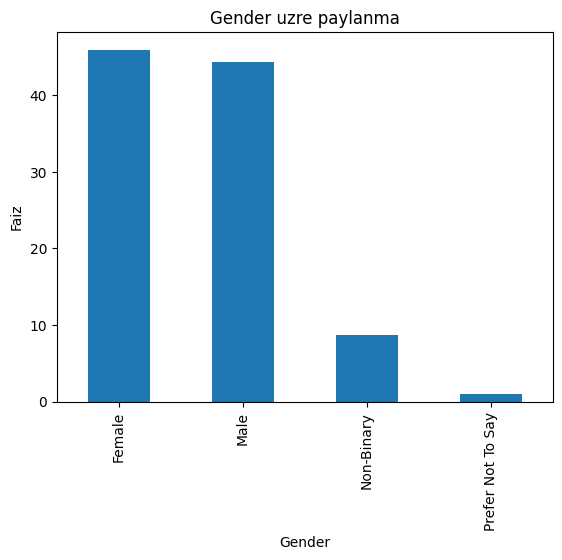

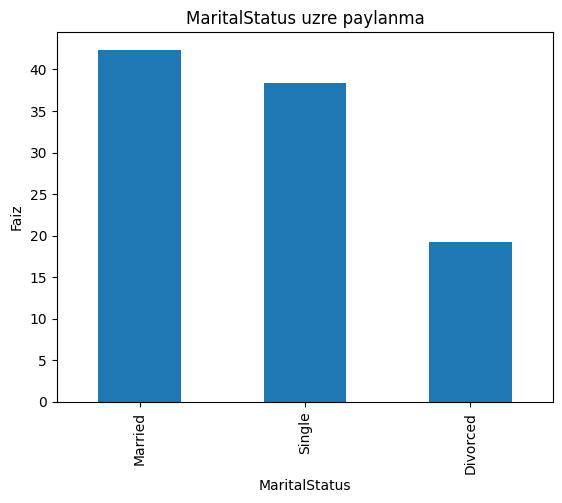

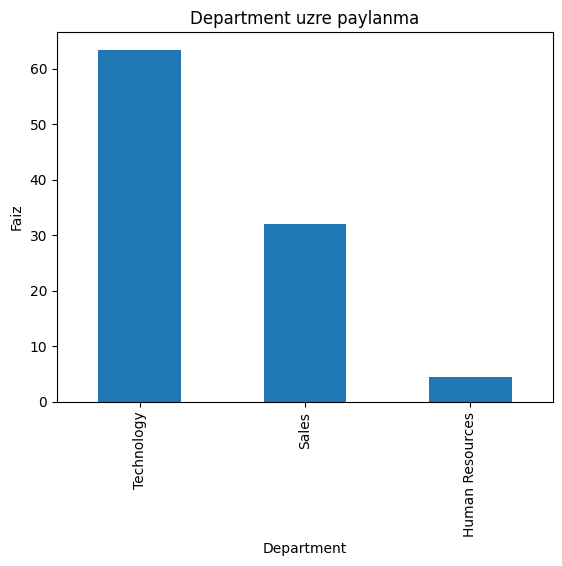

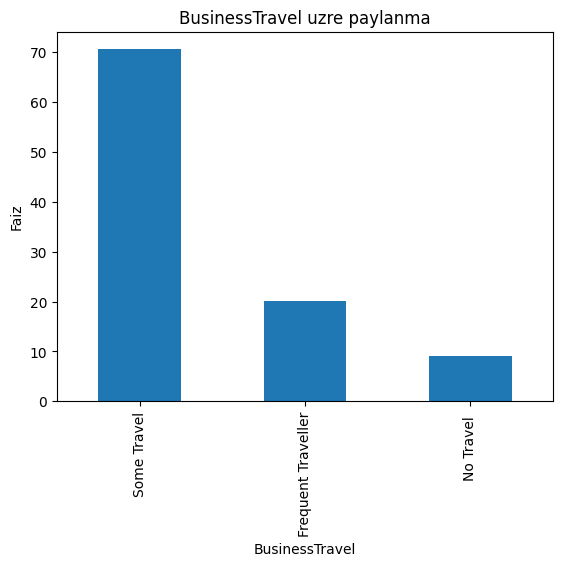

In [4]:
kataqoriyalar = ["Gender","MaritalStatus","Department","BusinessTravel"]
for col in kataqoriyalar:
    print(f"\n")
    print(round(df[col].value_counts(normalize=True)*100,2))

for cols in kataqoriyalar:
    (df[cols].value_counts(normalize=True)*100).plot(kind="bar")
    plt.title(cols + " uzre paylanma")
    plt.ylabel("Faiz")
    plt.show()


2.	Işçilərin yaş bölgüsünü araşdırın. (Min,Max,Ortalama,Dagilma) 

Minimum yas 18
Maksimum yas 51
yas ortalamsi 30.6
dagilma 7.99


Text(0.5, 0, 'Yas')

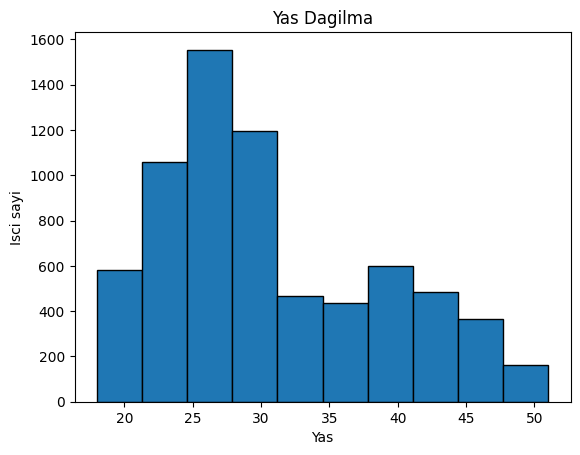

In [5]:
print("Minimum yas",df["Age"].min())
print("Maksimum yas",df["Age"].max())
print("yas ortalamsi",round(df["Age"].mean(),2))
print("dagilma",round(df["Age"].std(),2))
df["Age"].describe()
plt.hist(df["Age"],bins=10,edgecolor="black")
plt.title("Yas Dagilma")
plt.ylabel("Isci sayi")
plt.xlabel("Yas")

3.	İşçi qüvvəsində gender balansını vizuallaşdırma təhlil edin.

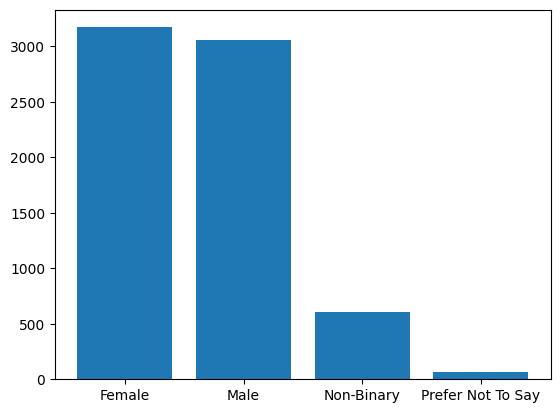

In [6]:
gender_counts = df["Gender"].value_counts()
plt.bar(gender_counts.index,gender_counts.values)
plt.show()


4.	İşçilərin müxtəlif şöbələr və vəzifə rolları üzrə bölgüsünü araşdırın. 

C:\Users\User\AppData\Local\Temp\ipykernel_10428\145365964.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


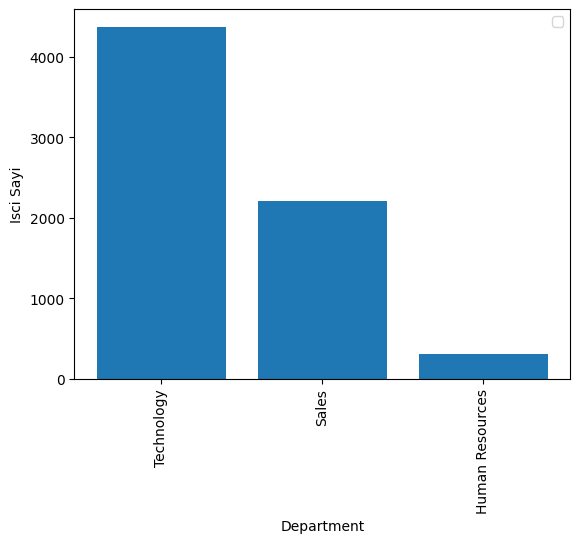

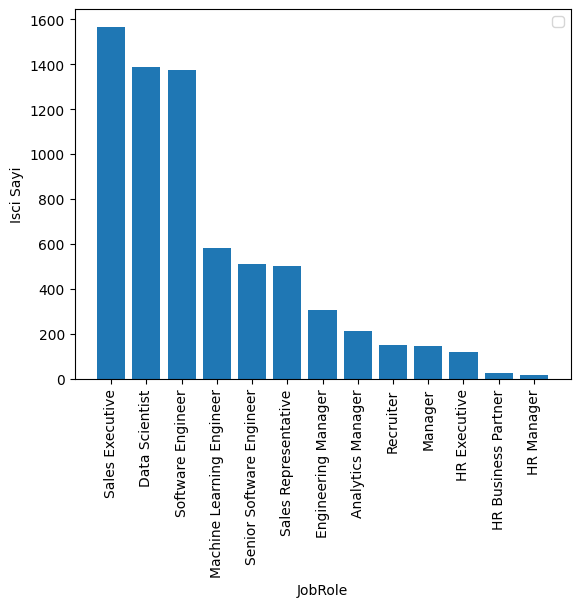

In [7]:
columns = ["Department","JobRole"]
# df.columns
for coll in columns:
    cool = df[coll].value_counts()
    plt.bar(cool.index,cool.values)
    plt.legend()
    plt.xticks(rotation=90)
    plt.ylabel("Isci Sayi")
    plt.xlabel(coll)
    plt.show()


5.	İşçilərin təhsil səviyyələrinin bölüşdürülməsini araşdırın.

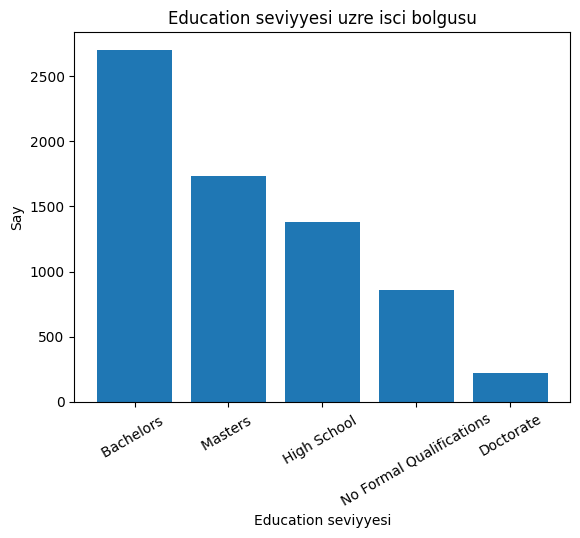

In [8]:
edu_counts = df["EducationLevel"].value_counts()
plt.bar(edu_counts.index,edu_counts.values)
plt.title("Education seviyyesi uzre isci bolgusu")
plt.xlabel("Education seviyyesi")
plt.ylabel("Say")
plt.xticks(rotation=30)
plt.show()

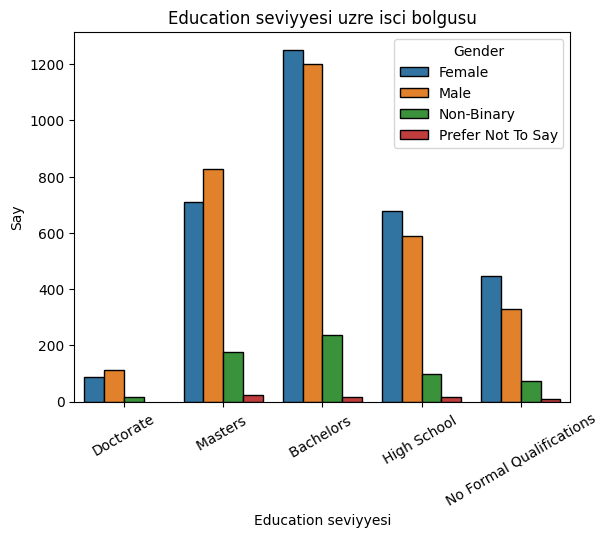

In [9]:
sns.countplot(df,x="EducationLevel",hue="Gender",edgecolor="black")
plt.title("Education seviyyesi uzre isci bolgusu")
plt.xlabel("Education seviyyesi")
plt.ylabel("Say")
plt.xticks(rotation=30)
plt.show()

6.	Müxtəlif qruplar üçün orta məmnunluq səviyyələrini hesablayın (məsələn, şöbə, cins, təhsil səviyyəsi üzrə).

In [10]:
groups = ["Department","Gender","EducationLevel"]
for group in groups:
    print(f"\n{group} üzrə orta Job Satisfaction")
    print(df.groupby(group)["JobSatisfaction"].mean())



Department üzrə orta Job Satisfaction
Department
Human Resources    3.435644
Sales              3.422057
Technology         3.434578
Name: JobSatisfaction, dtype: float64

Gender üzrə orta Job Satisfaction
Gender
Female               3.437075
Male                 3.427898
Non-Binary           3.404075
Prefer Not To Say    3.491803
Name: JobSatisfaction, dtype: float64

EducationLevel üzrə orta Job Satisfaction
EducationLevel
Bachelors                   3.440015
Doctorate                   3.298578
High School                 3.460400
Masters                     3.435146
No Formal Qualifications    3.377381
Name: JobSatisfaction, dtype: float64


7.	Məmnunluq səviyyələri ilə attrition arasındakı əlaqəni araşdırın.

Attrition            No  Yes
SatisfactionLevel           
Dissatisfied       1122  565
Neutral            1070  556
Satisfied          1137  553
Very Dissatisfied    97   40
Very Satisfied     1022  547


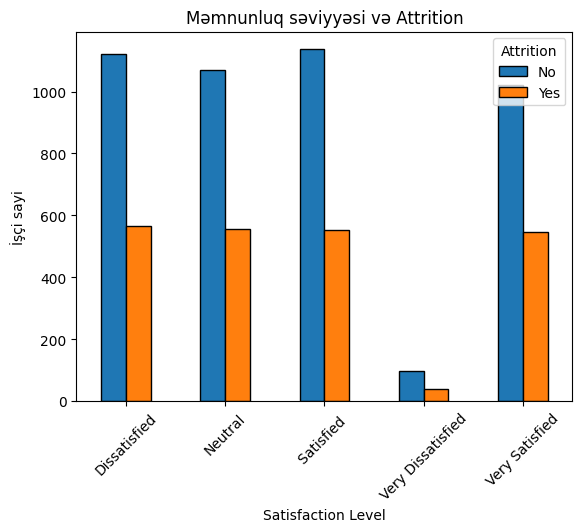

In [11]:

elaqe = pd.crosstab(df["SatisfactionLevel"], df["Attrition"])
print(elaqe)
elaqe.plot(kind="bar",edgecolor = "black")
plt.title("Məmnunluq səviyyəsi və Attrition")
plt.xlabel("Satisfaction Level")
plt.ylabel("İşçi sayi")
plt.xticks(rotation=45)
plt.show()

8.	SelfRating və ManagerRating-in paylanmasını yoxlayın. 

ManagerRating   2.0   3.0   4.0   5.0
SelfRating                           
3.0            1192  1097     1     0
4.0               0  1126  1110     0
5.0               0     0  1109  1074


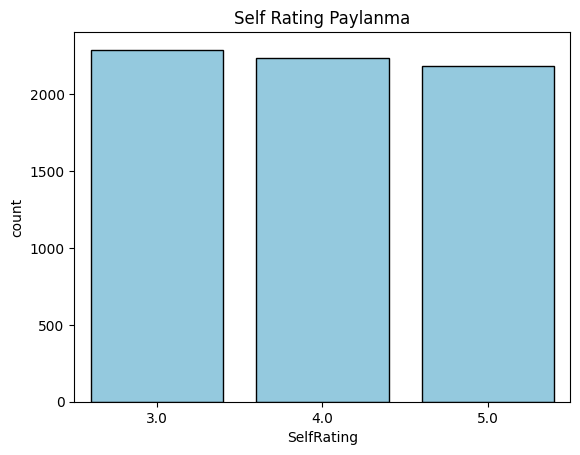

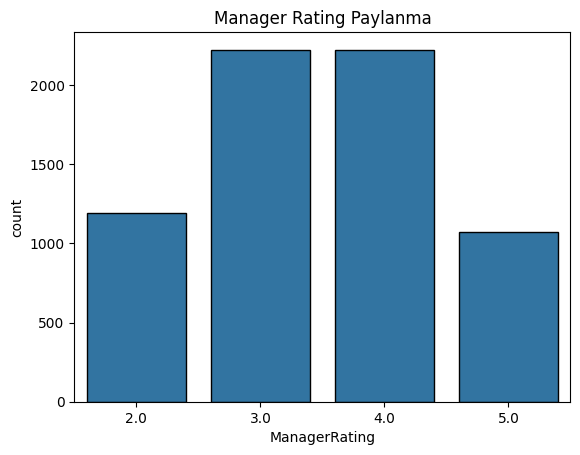

In [12]:
df.columns
rating_matrix = pd.crosstab(df['SelfRating'], df['ManagerRating'])
print(rating_matrix)

sns.countplot(data=df, x="SelfRating",color='skyblue',edgecolor="black")
plt.title("Self Rating Paylanma")
plt.show()


sns.countplot(data=df, x="ManagerRating",edgecolor="black")
plt.title("Manager Rating Paylanma")
plt.show()

10.Şöbə və iş roluna görə orta reytinqləri hesablayın.

                 SelfRating  ManagerRating
Department                                
Human Resources    3.990099       3.442244
Sales              3.973476       3.449977
Technology         3.988959       3.487432


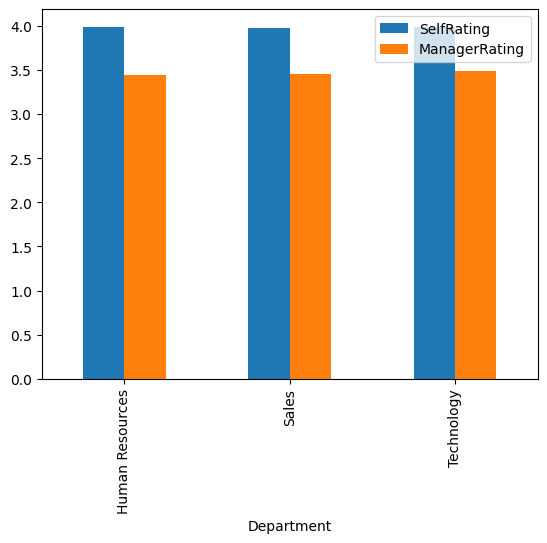

In [13]:
x = df.groupby("Department")[["SelfRating","ManagerRating"]].mean()
print(x)
ax = x.plot(kind="bar")


                           SelfRating  ManagerRating
JobRole                                             
Analytics Manager            4.009615       3.456731
Data Scientist               4.006618       3.526471
Engineering Manager          3.976821       3.460265
HR Business Partner          3.739130       3.130435
HR Executive                 4.017391       3.460870
HR Manager                   4.000000       3.375000
Machine Learning Engineer    3.973118       3.491039
Manager                      3.878571       3.357143
Recruiter                    4.006711       3.483221
Sales Executive              3.996713       3.473373
Sales Representative         3.928425       3.404908
Senior Software Engineer     3.975709       3.439271
Software Engineer            3.982009       3.474513


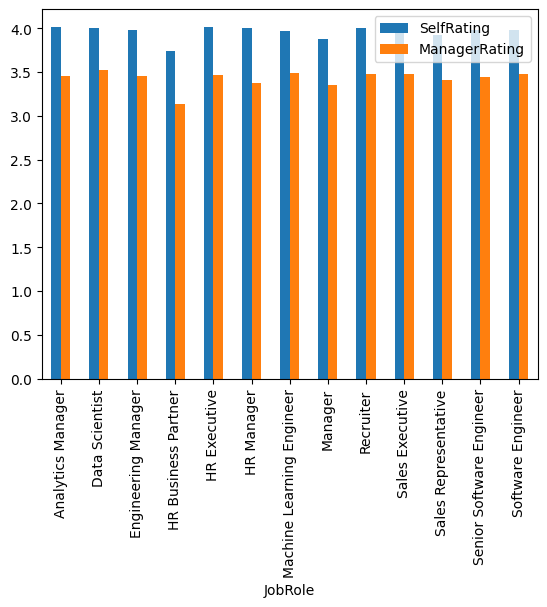

In [14]:
y = df.groupby("JobRole")[["SelfRating","ManagerRating"]].mean()
print(y)
ay = y.plot(kind="bar")
plt.show()

11.	Məmnuniyyət və reytinq səviyyələrinin paylanmasını göstərmək üçün bar diaqramları və ya histoqramlar kimi vizuallaşdırmalar yaradın.

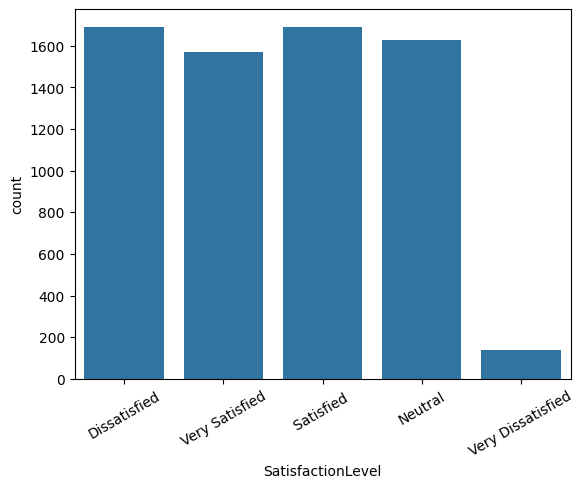

In [15]:
sns.countplot(data=df, x="SatisfactionLevel")
plt.xticks(rotation=30)
plt.show()

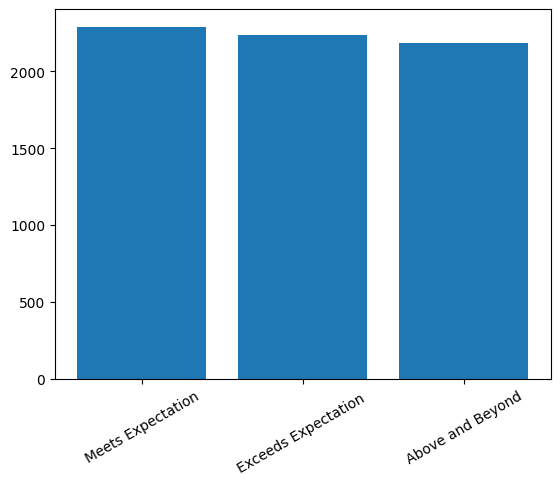

In [16]:
counts = df["SelfRatingLevel"].value_counts()
plt.bar(counts.index,counts.values)
plt.xticks(rotation=30)

plt.show()

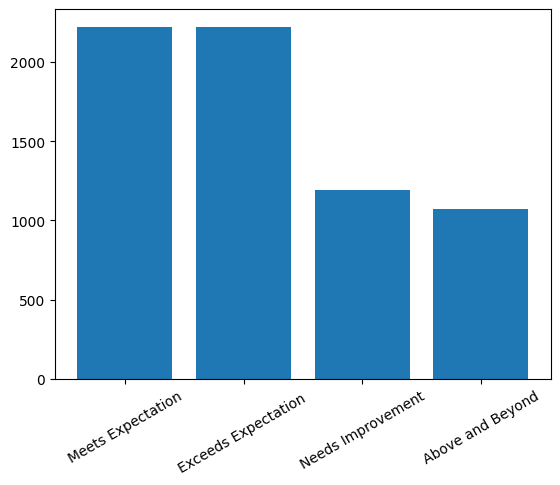

In [17]:
counts2 = df["ManagerRatingLevel"].value_counts()
plt.bar(counts2.index,counts2.values)
plt.xticks(rotation=30)
plt.show()

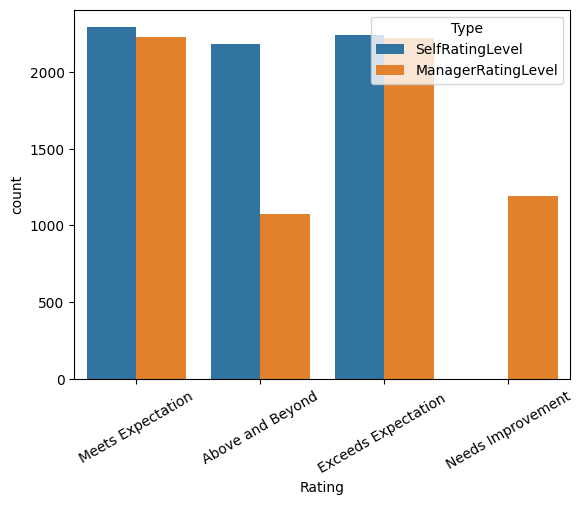

In [18]:
x = df[["SelfRatingLevel", "ManagerRatingLevel"]].melt(
    var_name="Type",
    value_name="Rating"
)
sns.countplot(data=x, x="Rating", hue="Type")
plt.xticks(rotation=30)
plt.show()

12.	Departamentin fəaliyyətini, iş məmnunluğunu və işdən çıxma dərəcələrini qiymətləndirin.

                 SelfRating  ManagerRating
Department                                
Human Resources        3.99           3.44
Sales                  3.97           3.45
Technology             3.99           3.49


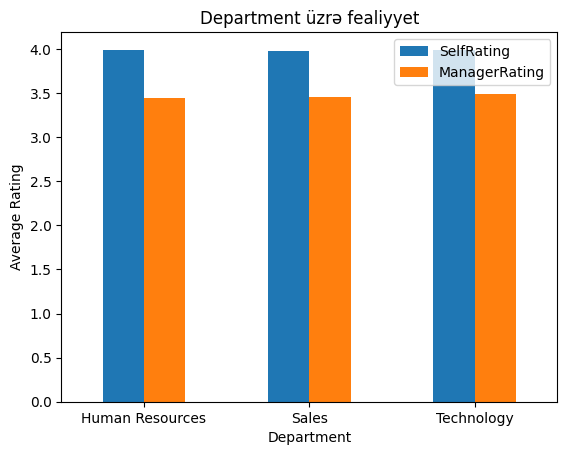

In [19]:
performance = df.groupby("Department")[["SelfRating","ManagerRating"]].mean().round(2)

print(performance)
performance.plot(kind="bar")
plt.title("Department üzrə fealiyyet")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.show()

Department
Human Resources    3.44
Sales              3.42
Technology         3.43
Name: JobSatisfaction, dtype: float64


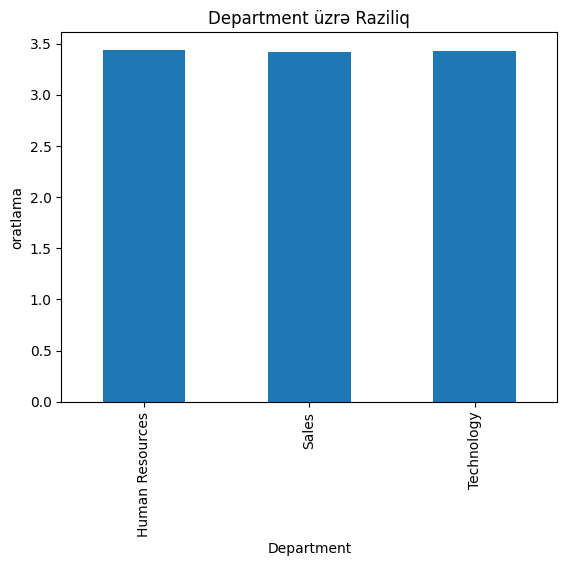

In [20]:
satisfaction = df.groupby("Department")["JobSatisfaction"].mean().round(2)

print(satisfaction)
satisfaction.plot(kind="bar")

plt.title("Department üzrə Raziliq")
plt.ylabel("oratlama")

plt.show()

Attrition          No   Yes
Department                 
Human Resources   198   115
Sales            1332   879
Technology       3108  1267


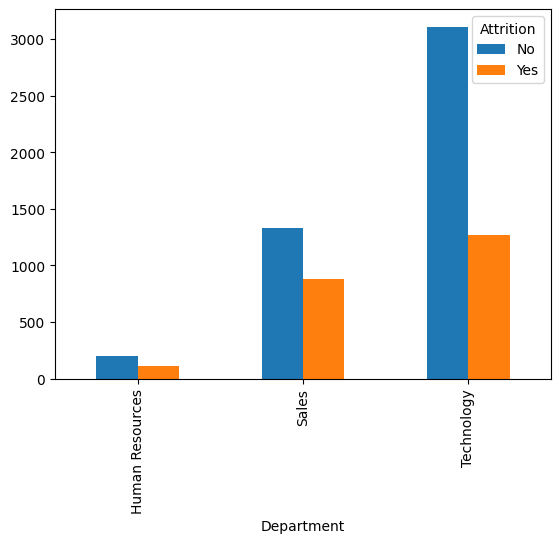

In [21]:
attrition = pd.crosstab(df["Department"], df["Attrition"])
print(attrition)
attrition.plot(kind="bar")
plt.show()

13.	Yüksək nəticə göstərən və aşağı nəticə göstərən şöbələri müəyyən edin. 

Department
Human Resources    3.44
Sales              3.45
Technology         3.49
Name: ManagerRating, dtype: float64
En yüksək nəticə göstərən şöbə - Technology: 3.49
En aşağı nəticə göstərən şöbə - Human Resources: 3.44


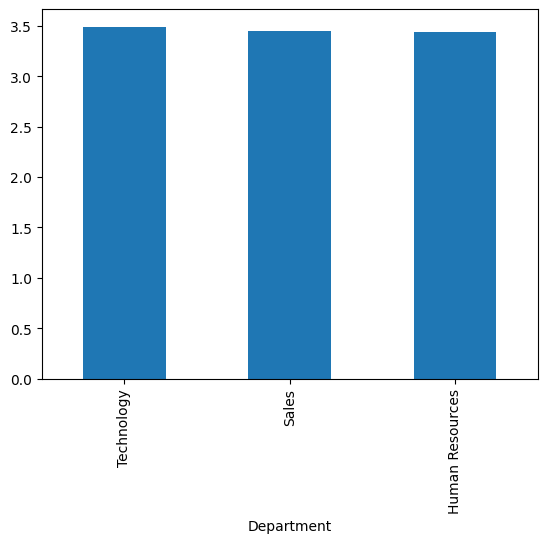

In [22]:
Rating = df.groupby("Department")["ManagerRating"].mean().round(2)
Rating.round(2).sort_values(ascending=False).plot(kind="bar")
print(Rating)
print(f"En yüksək nəticə göstərən şöbə - {Rating.idxmax()}: {Rating.max()}")
print(f"En aşağı nəticə göstərən şöbə - {Rating.idxmin()}: {Rating.min()}")

14.Təşkilat daxilində gender bölgüsü, maaş fərqləri və müxtəlifliyi təhlil edin 

Gender
Female               45.96
Male                 44.33
Non-Binary            8.75
Prefer Not To Say     0.96
Name: proportion, dtype: float64


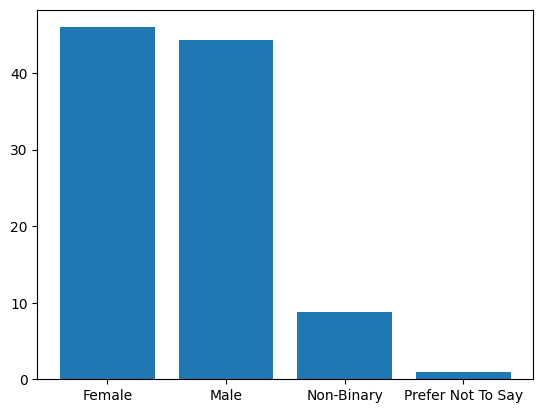

In [23]:
bolgu = (df.groupby("Gender").size()/df.groupby("Gender").size().sum()*100).round(2)
gender_bolgu = (df['Gender'].value_counts(normalize=True) * 100).round(2)
print(gender_bolgu)
plt.bar(bolgu.index,bolgu.values)
plt.show()

Gender
Female               107653.37
Male                 111037.28
Non-Binary           122356.17
Prefer Not To Say    155514.12
Name: Salary, dtype: float64


<Axes: xlabel='Gender'>

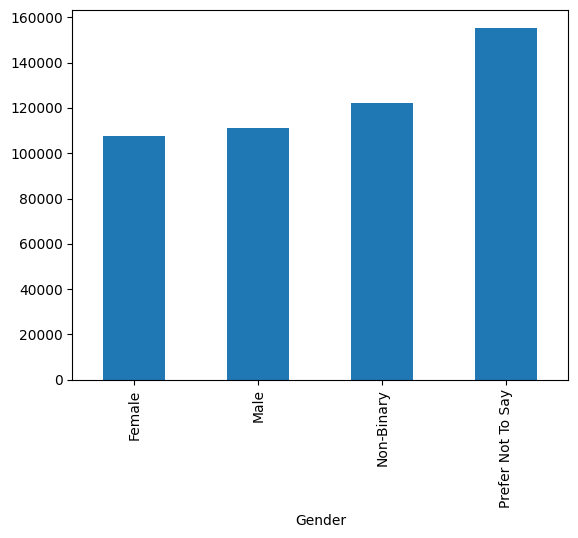

In [24]:
gender_salary = df.groupby('Gender')['Salary'].mean().round(2)
print(gender_salary)
df.groupby("Gender")["Salary"].mean().round(2).plot(kind="bar")

15.Gender və ya müxtəlifliyin işdən məmnunluq, performans və ya attrition-da
rol oynayıb-oynamadığını qiymətləndirin.


Gender
Female               31.22
Male                 35.64
Non-Binary           29.97
Prefer Not To Say     0.00
Name: Attrition, dtype: float64


Text(0.5, 0, 'Gender')

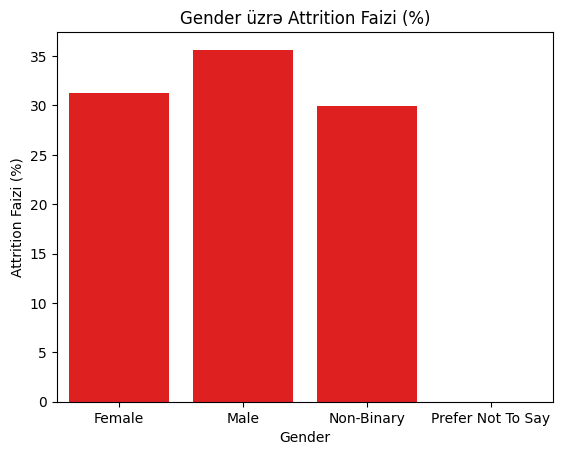

In [25]:
gender_attrition = df.groupby('Gender')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(2)
print(gender_attrition)
sns.barplot(x=gender_attrition.index, y=gender_attrition.values,color='red')
plt.title('Gender üzrə Attrition Faizi (%)')
plt.ylabel('Attrition Faizi (%)')
plt.xlabel('Gender')



# satisfaction = df.groupby("Gender")["JobSatisfaction"].mean().round(2)
# satisfaction.plot(kind="bar")
# plt.show()